# Flight Delay Prediction — Phase 1 (Machine Learning)

**Project 21:** Flight Delay Prediction via Gradient Boosting and Temporal Deep Learning

**Goal:** predict whether a flight will **arrive 15 or more minutes late**, using only information that is known
**before the flight departs**.

**Dataset:** Flights 2013 (`nycflights13`) — every flight that left a New York City airport (JFK, LGA, EWR) in 2013.

**Models (Phase 1):** Logistic Regression (baseline) and XGBoost.

### Contents
1. Load the data
2. Data quality checks
3. Exploratory Data Analysis (EDA)
4. Removing data leakage
5. Feature engineering
6. Train / validation / test split by date
7. Models: Logistic Regression and XGBoost
8. Evaluation and calibration
9. Conclusion

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nycflights13 import flights

sns.set_style("whitegrid")
os.makedirs("figures", exist_ok=True)
RANDOM_STATE = 42

## 1. Load the data

Each row is one scheduled flight. The `flights` table has 19 columns: the date, scheduled and actual departure/arrival
times, the delays, carrier, flight number, plane tail number, origin, destination, air time and distance.

In [2]:
df = flights.copy()
print("Shape:", df.shape)
df.head()

Shape: (336776, 19)


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01T10:00:00Z
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01T10:00:00Z
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01T10:00:00Z
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01T10:00:00Z
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01T11:00:00Z


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336776 entries, 0 to 336775
Data columns (total 19 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   year            336776 non-null  int64  
 1   month           336776 non-null  int64  
 2   day             336776 non-null  int64  
 3   dep_time        328521 non-null  float64
 4   sched_dep_time  336776 non-null  int64  
 5   dep_delay       328521 non-null  float64
 6   arr_time        328063 non-null  float64
 7   sched_arr_time  336776 non-null  int64  
 8   arr_delay       327346 non-null  float64
 9   carrier         336776 non-null  str    
 10  flight          336776 non-null  int64  
 11  tailnum         334264 non-null  str    
 12  origin          336776 non-null  str    
 13  dest            336776 non-null  str    
 14  air_time        327346 non-null  float64
 15  distance        336776 non-null  int64  
 16  hour            336776 non-null  int64  
 17  minute          33677

## 2. Data quality checks

We check for missing values and duplicate rows.

In [4]:
missing = df.isna().sum()
print(missing[missing > 0])
print("\nDuplicate rows:", df.duplicated().sum())

dep_time     8255
dep_delay    8255
arr_time     8713
arr_delay    9430
tailnum      2512
air_time     9430
dtype: int64

Duplicate rows: 0


- About 8,255 flights have no `dep_time` — these flights were **cancelled**.
- About 9,430 flights have no `arr_delay` — cancelled flights plus a few **diverted** flights that never arrived at the planned destination.
- There are no duplicate rows.

Our target needs the arrival delay, so we **drop flights without an `arr_delay`** (cancelled/diverted flights are a
different problem). Missing `tailnum` values do not matter because we do not use that column.

In [5]:
df = df.dropna(subset=["arr_delay"]).copy()

# Target: 1 if the flight arrived 15+ minutes late (the US Department of Transportation definition of "delayed")
df["delayed"] = (df["arr_delay"] >= 15).astype(int)

# A proper date column, used for EDA, features and the date-based split
df["date"] = pd.to_datetime(df[["year", "month", "day"]])

print("Flights left:", len(df))
print("Delayed share:", round(df["delayed"].mean(), 3))

Flights left: 327346
Delayed share: 0.245


## 3. Exploratory Data Analysis

### 3.1 Target balance and the distribution of arrival delays

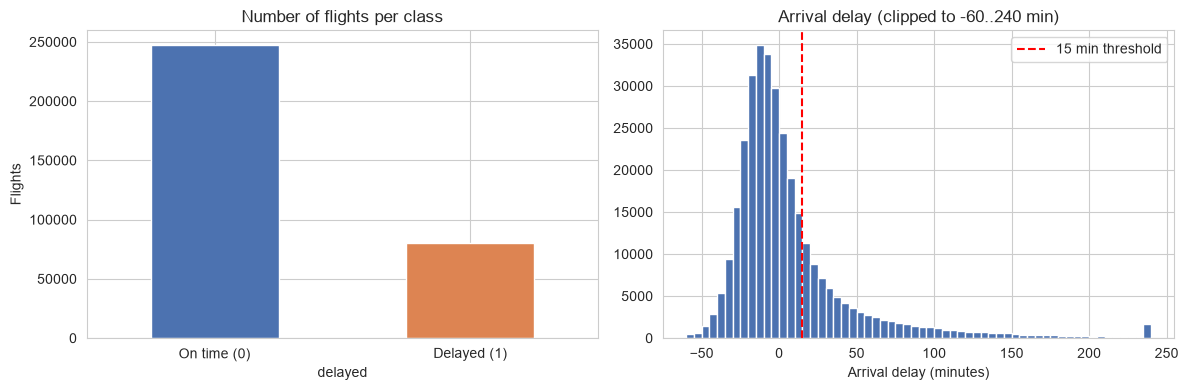

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["delayed"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_xticks([0, 1], ["On time (0)", "Delayed (1)"], rotation=0)
axes[0].set_title("Number of flights per class")
axes[0].set_ylabel("Flights")

axes[1].hist(df["arr_delay"].clip(-60, 240), bins=60, color="#4C72B0")
axes[1].axvline(15, color="red", linestyle="--", label="15 min threshold")
axes[1].set_title("Arrival delay (clipped to -60..240 min)")
axes[1].set_xlabel("Arrival delay (minutes)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/target_distribution.png", dpi=150)
plt.show()

- Only about **1 in 4 flights is delayed**, so the classes are **imbalanced**. Accuracy would be misleading
  (always predicting "on time" already gives ~75%), so we use PR AUC and ROC AUC later.
- Most flights arrive early or on time; delays have a **long right tail** (a few flights are hours late).

### 3.2 Delay rate by month, weekday and hour

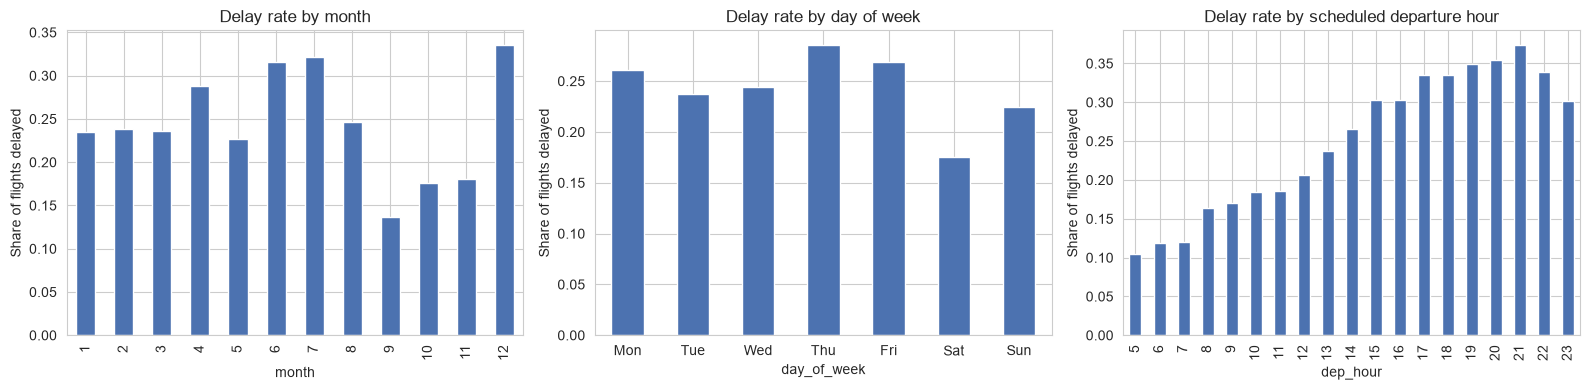

In [7]:
df["day_of_week"] = df["date"].dt.dayofweek   # 0 = Monday
df["dep_hour"] = df["sched_dep_time"] // 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("month")["delayed"].mean().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Delay rate by month")
df.groupby("day_of_week")["delayed"].mean().plot(kind="bar", ax=axes[1], color="#4C72B0")
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
axes[1].set_title("Delay rate by day of week")
df.groupby("dep_hour")["delayed"].mean().plot(kind="bar", ax=axes[2], color="#4C72B0")
axes[2].set_title("Delay rate by scheduled departure hour")
for ax in axes:
    ax.set_ylabel("Share of flights delayed")

plt.tight_layout()
plt.savefig("figures/delay_by_time.png", dpi=150)
plt.show()

- **Month:** December, July and June are the worst months (over 30% delayed); September–November are the calmest (under 20%).
  The delay rate changes a lot over the year, which matters for our date-based split.
- **Day of week:** Saturday is the best day (~18% delayed); Thursday and Monday are the worst.
- **Hour:** the strongest pattern — early morning flights are rarely late, and the delay rate keeps **rising through
  the day** as delays build up across the network.

### 3.3 Delay rate by carrier and origin airport

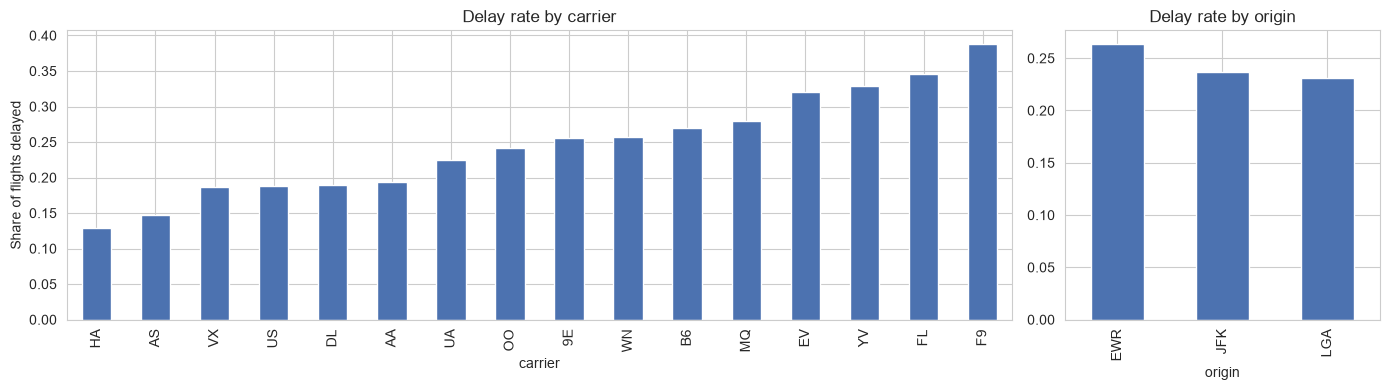

,delay_rate,flights
carrier,,
HA,0.129,342
AS,0.147,709
VX,0.187,5116
US,0.188,19831
DL,0.190,47658
AA,0.194,31947
UA,0.225,57782
OO,0.241,29
9E,0.256,17294


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})

carrier_stats = df.groupby("carrier")["delayed"].agg(["mean", "size"]).sort_values("mean")
carrier_stats["mean"].plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Delay rate by carrier")
axes[0].set_ylabel("Share of flights delayed")

df.groupby("origin")["delayed"].mean().plot(kind="bar", ax=axes[1], color="#4C72B0")
axes[1].set_title("Delay rate by origin")

plt.tight_layout()
plt.savefig("figures/delay_by_carrier_origin.png", dpi=150)
plt.show()

carrier_stats.rename(columns={"mean": "delay_rate", "size": "flights"}).round(3)

- Carriers differ a lot: some small carriers (e.g. FL, F9, EV) are delayed far more often than others (e.g. HA, AS, US).
- **EWR** (Newark) has the highest delay rate of the three airports.

These patterns suggest **carrier, airport and time of day** are useful features.

## 4. Removing data leakage

We make the prediction **before the flight departs** (for example, on the morning of the flight day).
Any column that is only known *after* departure would leak the answer into the model and give unrealistically good
results, so it must be removed:

| Column | Why it is removed |
|--------|-------------------|
| `dep_time`, `dep_delay` | Actual departure — only known once the plane leaves |
| `arr_time`, `arr_delay` | Actual arrival — this *is* the answer (`arr_delay` was only used to build the target) |
| `air_time` | Actual flight time — only known after landing |
| `tailnum` | The plane can be swapped at the last minute; also has ~4,000 unique values |
| `flight` | Just an ID number, no meaning as a number |
| `time_hour`, `year`, `day`, `hour`, `minute` | Duplicates of other date/time columns (and `year` is always 2013) |

In [9]:
leaky_columns = ["dep_time", "dep_delay", "arr_time", "arr_delay", "air_time"]
other_dropped = ["tailnum", "flight", "time_hour", "year", "day", "hour", "minute"]

df = df.drop(columns=leaky_columns + other_dropped)
df.columns.tolist()

['month',
 'sched_dep_time',
 'sched_arr_time',
 'carrier',
 'origin',
 'dest',
 'distance',
 'delayed',
 'date',
 'day_of_week',
 'dep_hour']

## 5. Feature engineering

All features are built from the **flight schedule** or from **past days only**.

**5.1 Calendar and schedule features**
- `day_of_week`, `is_weekend`
- `dep_hour`, `arr_hour` — scheduled departure and arrival hour

We do **not** use `month` as a feature: with a date-based split the test months (Nov–Dec) never appear in training,
so the model could not learn anything useful from them.

In [10]:
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
df["arr_hour"] = df["sched_arr_time"] // 100

**5.2 Airport congestion features** (known from the schedule in advance)
- `origin_hour_flights` — how many flights are scheduled to leave the same airport in the same hour
- `origin_day_flights` — how many flights are scheduled to leave the same airport on that day

In [11]:
df["origin_hour_flights"] = df.groupby(["date", "origin", "dep_hour"])["carrier"].transform("size")
df["origin_day_flights"] = df.groupby(["date", "origin"])["carrier"].transform("size")

df[["origin_hour_flights", "origin_day_flights"]].describe().round(1)

,origin_hour_flights,origin_day_flights
count,327346.0,327346.0
mean,20.0,304.7
std,5.9,37.4
min,1.0,61.0
25%,17.0,287.0
50%,20.0,307.0
75%,24.0,331.0
max,38.0,375.0


**5.3 Historical delay features**

How delayed has this carrier / airport / destination been **recently**? For each one we compute the share of delayed
flights over the **previous 7 days**.

To avoid leakage we first compute one delay rate per day, then `shift(1)` so that a flight on day *d* only sees
days *d-1, d-2, ...* — never its own day or the future.

In [12]:
def add_past_delay_rate(df, col, window=7):
    """Share of delayed flights for each value of `col` over the previous `window` days (today excluded)."""
    daily = df.groupby([col, "date"])["delayed"].mean().reset_index().sort_values([col, "date"])
    new_col = f"{col}_delay_rate_7d"
    daily[new_col] = (daily.groupby(col)["delayed"]
                           .transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean()))
    return df.merge(daily[[col, "date", new_col]], on=[col, "date"], how="left")

for col in ["carrier", "origin", "dest"]:
    df = add_past_delay_rate(df, col)

df[["date", "carrier", "carrier_delay_rate_7d", "origin_delay_rate_7d", "dest_delay_rate_7d"]].head()

,date,carrier,carrier_delay_rate_7d,origin_delay_rate_7d,dest_delay_rate_7d
0,2013-01-01,UA,NaN,NaN,NaN
1,2013-01-01,UA,NaN,NaN,NaN
2,2013-01-01,AA,NaN,NaN,NaN
3,2013-01-01,B6,NaN,NaN,NaN
4,2013-01-01,DL,NaN,NaN,NaN


The first day of the year (and the first day of a new route) has no history, so these values are `NaN`. We fill them
after the split using the **training-set average**, so no test information is used.

In [13]:
# Final feature list
numeric_features = ["day_of_week", "is_weekend", "dep_hour", "arr_hour", "distance",
                    "origin_hour_flights", "origin_day_flights",
                    "carrier_delay_rate_7d", "origin_delay_rate_7d", "dest_delay_rate_7d"]
categorical_features = ["carrier", "origin", "dest"]

# Sanity check: no leaky column is used as a feature
assert not set(leaky_columns) & set(numeric_features + categorical_features)

df[numeric_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
day_of_week,327346.0,2.90,1.99,0.00,1.00,3.00,5.00,6.00
is_weekend,327346.0,0.25,0.44,0.00,0.00,0.00,1.00,1.00
dep_hour,327346.0,13.14,4.66,5.00,9.00,13.00,17.00,23.00
arr_hour,327346.0,15.04,4.97,0.00,11.00,15.00,19.00,23.00
distance,327346.0,1048.37,735.91,80.00,509.00,888.00,1389.00,4983.00
origin_hour_flights,327346.0,20.05,5.90,1.00,17.00,20.00,24.00,38.00
origin_day_flights,327346.0,304.71,37.38,61.00,287.00,307.00,331.00,375.00
carrier_delay_rate_7d,326512.0,0.25,0.11,0.00,0.16,0.23,0.31,1.00
origin_delay_rate_7d,326515.0,0.24,0.09,0.06,0.18,0.24,0.30,0.55
dest_delay_rate_7d,326496.0,0.25,0.12,0.00,0.16,0.23,0.32,1.00


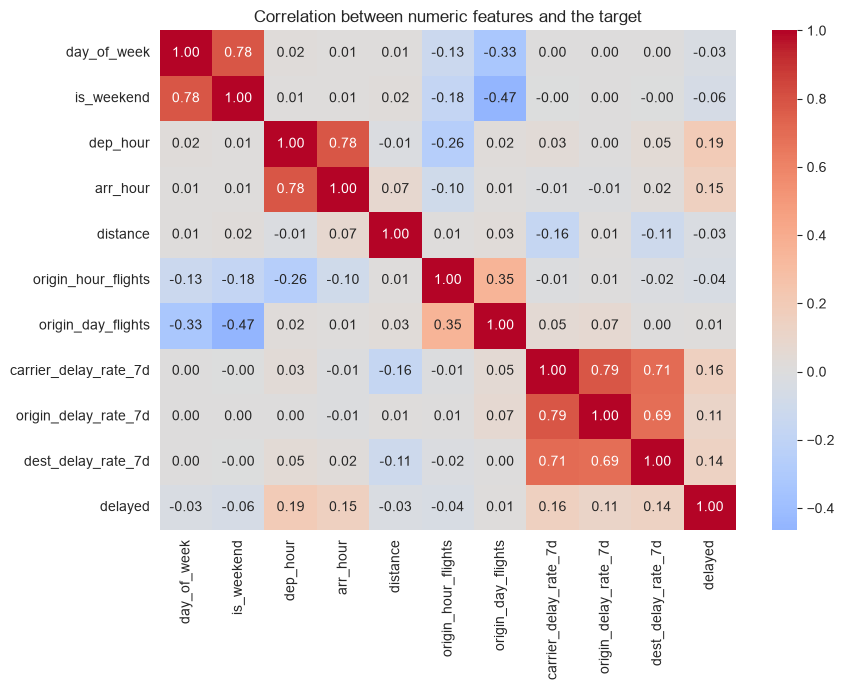

In [14]:
corr = df[numeric_features + ["delayed"]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features and the target")
plt.tight_layout()
plt.savefig("figures/correlation.png", dpi=150)
plt.show()

- `dep_hour` and `arr_hour` are strongly correlated with each other (as expected) and have the highest correlation
  with `delayed` among the schedule features.
- The past delay rates are positively correlated with `delayed`: if a carrier or airport has been delayed recently,
  it tends to stay delayed.
- The congestion features have only a weak linear correlation with the target; they may still help tree models
  through interactions (e.g. a busy hour at a specific airport).
- All correlations are small (below 0.2): a single feature cannot predict delays well, which is why we combine them.

## 6. Train / validation / test split by date

Flights are ordered in time, so we **split by date instead of randomly**. A random split would let the model train on
flights from the same days it is tested on, which is not possible in real life (we cannot see the future).

| Set | Months | Used for |
|-----|--------|----------|
| Train | Jan – Aug | Fitting the models |
| Validation | Sep – Oct | Choosing hyper-parameters and calibrating probabilities |
| Test | Nov – Dec | Final evaluation, used only once |

In [15]:
train = df[df["month"] <= 8]
val = df[df["month"].isin([9, 10])]
test = df[df["month"] >= 11]

# Sanity check: the sets do not overlap in time
assert train["date"].max() < val["date"].min() and val["date"].max() < test["date"].min()

pd.DataFrame({
    "flights": [len(train), len(val), len(test)],
    "delayed_share": [train["delayed"].mean(), val["delayed"].mean(), test["delayed"].mean()],
}, index=["train", "validation", "test"]).round(3)

,flights,delayed_share
train,217727,0.264
validation,55628,0.157
test,53991,0.258


Note that the validation months (Sep–Oct) have far fewer delays than the test months (Nov–Dec). This is the real
seasonal pattern from the EDA, and it makes the test a realistic, slightly harder check.

Next we turn the categorical columns into one-hot (dummy) columns and fill the missing history values.

In [16]:
def make_features(data):
    X = pd.get_dummies(data[numeric_features + categorical_features], columns=categorical_features, dtype=int)
    return X

X_train = make_features(train)
# Validation/test must have exactly the same columns as training (unseen destinations become all zeros)
X_val = make_features(val).reindex(columns=X_train.columns, fill_value=0)
X_test = make_features(test).reindex(columns=X_train.columns, fill_value=0)

# Fill missing history values with the training average
history_cols = ["carrier_delay_rate_7d", "origin_delay_rate_7d", "dest_delay_rate_7d"]
train_means = X_train[history_cols].mean()
X_train = X_train.fillna(train_means)
X_val = X_val.fillna(train_means)
X_test = X_test.fillna(train_means)

y_train, y_val, y_test = train["delayed"], val["delayed"], test["delayed"]

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)

X_train: (217727, 131)  X_val: (55628, 131)  X_test: (53991, 131)
